---
title: "L4-01 · Structural causal models"
short_title: "Structural causal models"
subtitle: "A causal model is a set of mechanisms; an intervention replaces one mechanism and keeps the others, so seeing $X = x$ and setting $X = x$ can give different answers from the same model."
description: "Write a structural causal model, compute an intervention by replacing one structural equation, and compare the interventional distribution with the observational one."
tags: [level-4, coursebook]
---

(lesson-l4-01)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 90 minutes  
**Big idea.** A causal model is a set of mechanisms; an intervention replaces one mechanism and keeps the others, so seeing $X = x$ and setting $X = x$ can give different answers from the same model.  
**Before this lesson.** [L2-08](#lesson-l2-08), [L3-07](#lesson-l3-07)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Write the structural equations, background distribution and induced graph of a small structural causal model, and derive its observational distribution by substitution in topological order.
- Build the submodel $M_x$ for $do(X = x)$ and compute $P(Y \mid do(X = x))$ by hand and by simulation.
- Prove the truncated factorization for a Markovian model and use it to explain why $P(y \mid x)$ and $P(y \mid do(x))$ differ when $X$ and $Y$ share a cause.

## Why this matters

Here is a model in three lines: a fair coin $U$, then $X := U$, then $Y := 2X + U$. Fit a line to data from it and you get $Y = 3X$ exactly, with no error. A forecaster is delighted. A policy maker who reads the fitted line and decides to push $X$ from 0 to 1 expects $Y$ to rise by 3, but it rises by 2. Nothing was wrong with the data or the fit. The forecaster answered a question about *seeing* $X = 1$; the policy maker asked about *making* $X = 1$.

The extra 1 came from the background coin $U$, which raises both $X$ and $Y$. Records with $X = 1$ are records where the coin landed heads, so they carry the coin's direct contribution to $Y$ with them. Setting $X$ by hand breaks that link. A structural causal model makes the difference precise: it writes one mechanism per variable, and an intervention replaces exactly one mechanism. With that one idea, [L2-08](#lesson-l2-08)'s slogan that setting is not selecting becomes a calculation, and the rest of Level 4 (adjustment, frontdoor, counterfactuals) is built on it [@pearlcausality; @peters].

:::{dropdown} Key terms

**Structural causal model (SCM)**
: Background variables with a joint distribution, plus one assignment $V_i := f_i(\mathrm{PA}_i, U_i)$ per modeled variable.

**Endogenous and exogenous**
: Endogenous variables are explained inside the model; exogenous (background) variables $U$ are inputs whose distribution is given.

**Structural assignment**
: The rule $:=$ that computes a variable from its direct causes. It is directional: it is not an equation you may solve for either side.

**Intervention $do(X = x)$**
: Replace the assignment of $X$ by the constant $x$ and keep every other assignment and the background distribution.

**Submodel $M_x$**
: The model produced by that replacement; $P(V \mid do(X = x))$ is its distribution.

**Markovian model**
: An acyclic SCM whose background terms $U_1, \dots, U_n$ are jointly independent.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_01 as _lessonfigs

## Mechanisms written as assignments

A structural causal model describes how each modeled variable is produced. Every variable gets its own rule, and the rule names the variable's direct causes. We write the rule with $:=$ rather than $=$ because it only runs one way: $Y := 2X + U$ says that $Y$ is computed from $X$ and $U$, not that $X$ is computed from $Y$.

:::{prf:definition} Structural causal model
:label: def-l4-01-scm
A structural causal model $M = \langle U, V, F, P(U)\rangle$ consists of background (exogenous) variables $U$ with a joint distribution $P(U)$; modeled (endogenous) variables $V = \{V_1, \dots, V_n\}$; and, for each $V_i$, an assignment $V_i := f_i(\mathrm{PA}_i, U_i)$ with parents $\mathrm{PA}_i \subseteq V \setminus \{V_i\}$ and $U_i \subseteq U$. The **induced graph** $G(M)$ has an arrow $V_j \to V_i$ whenever $V_j \in \mathrm{PA}_i$. The model is **recursive** if $G(M)$ has no directed cycle, and **Markovian** if it is recursive and $U_1, \dots, U_n$ are jointly independent [@pearlcausality; @peters].
:::

:::{prf:proposition} A recursive model fixes one joint distribution
:label: prop-l4-01-unique
In a recursive SCM, each value $u$ of the background variables determines exactly one value $v = (v_1, \dots, v_n)$ of the modeled variables. Hence $P(U)$ induces a unique joint distribution $P_M(V)$, the **observational distribution**.
:::

:::{prf:proof}
An acyclic graph has a topological order: relabel so that every parent of $V_i$ has a smaller index. Fix $u$. Then $V_1$ has no modeled parents, so $v_1 = f_1(u_1)$ is determined. If $v_1, \dots, v_{i-1}$ are determined, the parents of $V_i$ are among them, so $v_i = f_i(\mathrm{pa}_i, u_i)$ is determined. By induction $v = s(u)$ for a function $s$, and $P_M(V = v) = P(U \in s^{-1}(v))$. Without acyclicity this fails: $X := Y$, $Y := 1 - X$ has no solution at all.
:::

$$
U \sim \mathrm{Bernoulli}(1/2), \qquad X := U, \qquad Y := 2X + U
$$ (eq-l4-01-toy)

Run the model [](#eq-l4-01-toy) on both values of the coin. If $U = 0$ then $X = 0$ and $Y = 0$; if $U = 1$ then $X = 1$ and $Y = 3$. Only those two rows ever occur, so $\mathbb{E}[Y \mid X = 1] - \mathbb{E}[Y \mid X = 0] = 3 - 0 = 3$. This is the observed contrast. The model $X := U$, $Y := 2X + U$ is recursive but not Markovian, because one background coin feeds both assignments.

:::{figure} ../../_static/animations/l4_01_scm_machine.mp4
:alt: A three-node graph U, X, Y with the equations U ~ Bernoulli(1/2), X := U, Y := 2X + U. Values flow along the arrows for U = 0 and U = 1. Then the arrow from U to X is cut and X := U becomes X := x.
:width: 100%

The same three lines answer two questions. Running the machine gives the observed contrast 3; cutting the arrow into $X$ and replacing $X := U$ by $X := x$ gives $\mathbb{E}[Y \mid do(X = x)] = 2x + \tfrac{1}{2}$, a contrast of 2.
:::

:::{dropdown} What the animation shows
The graph has a background node $U$ with arrows to $X$ and to $Y$, and an arrow from $X$ to $Y$. Under it are the assignments $U \sim \mathrm{Bernoulli}(1/2)$, $X := U$ and $Y := 2X + U$. The machine runs twice: with $U = 0$ a pulse travels along the arrows and gives $X = 0$, $Y = 0$; with $U = 1$ it gives $X = 1$, $Y = 3$. The observed contrast is written as $3 - 0 = 3$. Then a red cross cuts the arrow from $U$ to $X$, the arrow disappears, and the assignment $X := U$ turns into $X := x$. Under $do(X = 1)$ the outcome is 2 or 3 with mean 2.5; under $do(X = 0)$ it is 0 or 1 with mean 0.5. The boxed result is $\mathbb{E}[Y \mid do(X = x)] = 2x + \tfrac{1}{2}$: causal contrast 2, not the observed 3.
:::

## Interventions replace one mechanism

:::{prf:definition} Intervention and submodel
:label: def-l4-01-do
Let $X \subseteq V$ and let $x$ be a value of $X$. The **submodel** $M_x$ is $M$ with the assignment of every $V_i \in X$ replaced by the constant $V_i := x_i$; all other assignments and $P(U)$ stay as they were. The **interventional distribution** is $P(V \mid do(X = x)) := P_{M_x}(V)$. In the graph, $M_x$ deletes every arrow that points into $X$ and keeps all other arrows [@pearlcausality].
:::

Apply the definition to [](#eq-l4-01-toy). In $M_x$ the assignment $X := U$ becomes $X := x$, while $Y := 2X + U$ and the coin are untouched. So $Y = 2x + U$, and linearity of expectation from [L3-07](#lesson-l3-07) gives

$$
\mathbb{E}[Y \mid do(X = x)] = \mathbb{E}[2x + U] = 2x + \tfrac{1}{2}
$$ (eq-l4-01-toy-do)

The interventional means are $2.5$ and $0.5$, so the causal contrast is 2, while the observed contrast was 3. The gap of 1 is the coin's direct contribution, which rides along with $X$ in the records because $X$ copies the coin.

:::{important} Conditioning filters; intervening rebuilds
$P(Y \mid X = x)$ keeps the model $M$ and looks only at the rows where $X$ happened to equal $x$. $P(Y \mid do(X = x))$ runs a different model, $M_x$, on every row. The two agree when nothing else links $X$ to $Y$; [L4-02](#lesson-l4-02) and [L4-04](#lesson-l4-04) make that condition exact.
:::

```{mermaid}
graph LR
  subgraph M["observational model M"]
    Z1((Z)) --> X1((X))
    Z1 --> Y1((Y))
    X1 --> Y1
  end
  subgraph Mx["submodel M_x after do(X = x)"]
    Z2((Z)) --> Y2((Y))
    X2["X = x"] --> Y2
  end
```

*Graph surgery. On the left, $Z$ is a common cause of $X$ and $Y$. On the right, the intervention removes the only arrow into $X$ and fixes its value; the arrows out of $X$ and the mechanism of $Y$ are unchanged.*

:::{figure} ../../_static/animations/l4_01_graph_surgery.mp4
:alt: A graph with Z pointing to X and Y and X pointing to Y. Blue bars show P(Y=1 | X=x) of 0.20 and 0.70. The arrow from Z to X is cut, and orange bars show P(Y=1 | do(X=x)) of 0.35 and 0.55.
:width: 100%

Cut the arrow into $X$, replace its assignment, keep the rest. Seeing gives risks $0.20$ and $0.70$; doing gives $0.35$ and $0.55$. The interventional risk equals $0.5 \cdot 0.8 + 0.5 \cdot 0.3$, an average over $Z$ with the weights $Z$ has in the whole population.
:::

:::{dropdown} What the animation shows
On the left is the graph $Z \to X$, $Z \to Y$, $X \to Y$, with assignments $Z := U_Z$, $X := f_X(Z, U_X)$ and $Y := f_Y(X, Z, U_Y)$. On the right, blue bars rise to the observational risks $P(Y = 1 \mid X = 0) = 0.20$ and $P(Y = 1 \mid X = 1) = 0.70$. Then the arrow from $Z$ to $X$ flashes red, is crossed out and disappears, and the assignment of $X$ changes to $X := x$. Orange bars rise to the interventional risks $P(Y = 1 \mid do(X = 0)) = 0.35$ and $P(Y = 1 \mid do(X = 1)) = 0.55$. Two lines compare the contrasts: seeing $0.70 - 0.20 = 0.50$, doing $0.55 - 0.35 = 0.20$. The last formula shows why: $P(Y = 1 \mid do(X = 1)) = \sum_z P(Y = 1 \mid X = 1, z) P(z) = 0.5 \cdot 0.8 + 0.5 \cdot 0.3 = 0.55$.
:::

## The truncated factorization

The binary model in the animation is the course engine's model, `qcai.science.causal`: $Z \sim \mathrm{Bernoulli}(0.5)$; $P(X = 1 \mid Z = 1) = 0.8$ and $P(X = 1 \mid Z = 0) = 0.2$; and $P(Y = 1 \mid X, Z) = 0.1 + 0.2X + cZ$ with confounding strength $c = 0.5$. Each variable has its own independent background noise, so the model is Markovian. For Markovian models the observational distribution has a famous product form.

:::{prf:theorem} Markov factorization
:label: thm-l4-01-markov
If $M$ is Markovian, its observational distribution factorizes over the induced graph:
:::

$$
P(v_1, \dots, v_n) = \prod_{i=1}^{n} P(v_i \mid \mathrm{pa}_i)
$$ (eq-l4-01-markov)

:::{prf:proof}
Order the variables topologically. By the chain rule $P(v) = \prod_i P(v_i \mid v_1, \dots, v_{i-1})$. The earlier variables $V_1, \dots, V_{i-1}$ are functions of $U_1, \dots, U_{i-1}$ only (Proposition [](#prop-l4-01-unique)), and $U_i$ is independent of those. Given $V_1, \dots, V_{i-1}$, the value $V_i = f_i(\mathrm{pa}_i, U_i)$ therefore depends on the past only through $\mathrm{pa}_i$, and $P(v_i \mid v_1, \dots, v_{i-1}) = P(f_i(\mathrm{pa}_i, U_i) = v_i) = P(v_i \mid \mathrm{pa}_i)$.
:::

:::{prf:theorem} Truncated factorization
:label: thm-l4-01-truncated
Let $M$ be Markovian and $X \subseteq V$. For every $v$ that agrees with $x$ on $X$, $\; P(v \mid do(X = x)) = \prod_{i:\, V_i \notin X} P(v_i \mid \mathrm{pa}_i)$, and $P(v \mid do(X = x)) = 0$ for every other $v$. The factors are the observational conditionals of $M$, wherever $P(\mathrm{pa}_i) > 0$ [@pearlcausality; @peters].
:::

:::{prf:proof}
The submodel $M_x$ is again Markovian: its graph is $G(M)$ minus the arrows into $X$, and its background terms are the same independent $U_i$. Apply the Markov factorization to $M_x$. A variable in $X$ is the constant $x_i$, so its factor is $1$ if $v_i = x_i$ and $0$ otherwise. A variable outside $X$ keeps its assignment $f_i$ and its noise $U_i$, so its factor is $P_{M_x}(v_i \mid \mathrm{pa}_i) = P(f_i(\mathrm{pa}_i, U_i) = v_i) = P_M(v_i \mid \mathrm{pa}_i)$. This step is **modularity**: changing one mechanism leaves the others intact.
:::

:::{prf:corollary} Adjusting for the parents of the treatment
:label: cor-l4-01-parents
In a Markovian model, let $Y \ne X$ be a variable that is not a parent of $X$, and suppose $P(x \mid \mathrm{pa}_X) > 0$ for every $\mathrm{pa}_X$. Then $P(y \mid do(x)) = \sum_{\mathrm{pa}_X} P(y \mid x, \mathrm{pa}_X)\, P(\mathrm{pa}_X)$.
:::

:::{prf:proof}
Comparing the two factorizations, $P(v \mid do(x)) = P(v) / P(x \mid \mathrm{pa}_X)$ for every $v$ that agrees with $x$. Sum over all variables except $Y$ and $\mathrm{PA}_X$. The denominator does not depend on the summed variables, so $P(y, \mathrm{pa}_X \mid do(x)) = P(y, x, \mathrm{pa}_X) / P(x \mid \mathrm{pa}_X) = P(y \mid x, \mathrm{pa}_X) P(\mathrm{pa}_X)$. Summing over $\mathrm{pa}_X$ gives the claim.
:::

$$
P(Y{=}1 \mid do(X{=}1)) = \sum_{z} P(Y{=}1 \mid X{=}1, z)\, P(z) = 0.5 \cdot 0.8 + 0.5 \cdot 0.3 = 0.55
$$ (eq-l4-01-adjust)

Compare with seeing: $P(Y = 1 \mid X = 1) = \sum_z P(Y = 1 \mid X = 1, z) P(z \mid X = 1) = 0.8 \cdot 0.8 + 0.2 \cdot 0.3 = 0.70$. The only difference is the weight on $Z$: $P(z \mid X = 1)$ instead of $P(z)$. Among treated records, $Z = 1$ is over-represented (0.8 instead of 0.5), and $Z = 1$ raises the risk of $Y$ on its own. In the same way $P(Y = 1 \mid X = 0) = 0.20$ but $P(Y = 1 \mid do(X = 0)) = 0.35$.

:::{prf:remark} The toy model is not covered, and that is instructive
The theorem needs independent background terms. In $X := U$, $Y := 2X + U$ the shared coin breaks this. Making the coin a modeled node $U \to X$, $U \to Y$ restores the Markov property, but the corollary still cannot be applied: $P(X = 1 \mid U = 0) = 0$, so the positivity condition fails and $P(Y \mid X = 1, U = 0)$ is undefined. The model still answers $do(X = 1)$, because it states the mechanism of $Y$. Data alone could not.
:::

## Seeing drifts, doing stays

Now vary the confounding strength $c$, the amount by which $Z = 1$ raises the risk of $Y$. Bayes' rule gives $P(Z = 1 \mid X = 1) = 0.5 \cdot 0.8 / 0.5 = 0.8$ and $P(Z = 1 \mid X = 0) = 0.2$, whatever $c$ is. Therefore

$$
P(Y{=}1 \mid X{=}1) - P(Y{=}1 \mid X{=}0) = 0.2 + c\,[P(Z{=}1 \mid X{=}1) - P(Z{=}1 \mid X{=}0)] = 0.2 + 0.6c
$$ (eq-l4-01-contrast)

while the truncated factorization gives the causal risk difference $P(Y = 1 \mid do(X = 1)) - P(Y = 1 \mid do(X = 0)) = 0.2$ for every $c$. At $c = 0.5$ the observed contrast is $0.50$, a bias of $0.30$. At $c = 0$ the two agree, because then $Z$ no longer affects $Y$ and the path through $Z$ carries nothing.

:::{figure} ../../_static/animations/l4_01_confounding_sweep.mp4
:alt: A derivation that simplifies the observed contrast to 0.2 + 0.6c, then a graph where a blue point traces the rising line 0.2 + 0.6c while an orange dashed line stays at 0.2.
:width: 100%

The observed contrast $0.2 + 0.6c$ climbs with the confounding strength while the causal effect stays at $0.2$. At $c = 0.5$ the bias is $0.30$.
:::

:::{dropdown} What the animation shows
The top of the frame derives the observed contrast. $P(Y = 1 \mid X = 1) - P(Y = 1 \mid X = 0)$ equals $0.2 + c\,[P(Z = 1 \mid X = 1) - P(Z = 1 \mid X = 0)]$; the bracket becomes $(0.8 - 0.2)$ and then the line simplifies to $0.2 + 0.6c$. Beside it, the interventional contrast is $0.2$ for every $c$. Below, axes show confounding strength $c$ from 0 to 0.6 and risk difference from 0 to 0.6. An orange dashed line sits at 0.2. A blue point starts at $(0, 0.2)$ and traces a straight rising line while a readout shows $c$ and the observed contrast. At $c = 0.5$ it stops at $0.50$, and a red segment marks the bias $0.30$ between the two lines. The point then continues to $c = 0.6$, where the observed contrast is $0.56$.
:::


In [2]:
_show(_lessonfigs.see_vs_do())

**Explore.** Move the slider to change the confounding strength $c$. The blue bars are what you see in data; the orange bars are what an intervention would produce. The right panel tracks the two contrasts.

:::{dropdown} What the figure shows
The first panel has grouped bars for $X = 0$ and $X = 1$: blue for $P(Y = 1 \mid X = x)$ and orange for $P(Y = 1 \mid do(X = x))$. At $c = 0.5$ these are 0.20 and 0.70 (blue) and 0.35 and 0.55 (orange). The second panel plots the observed contrast $0.2 + 0.6c$ as a rising blue line and the causal effect 0.2 as a flat orange line for $c$ from 0 to 0.6, with a marker at the chosen $c$. At $c = 0$ every blue bar equals its orange partner.
:::


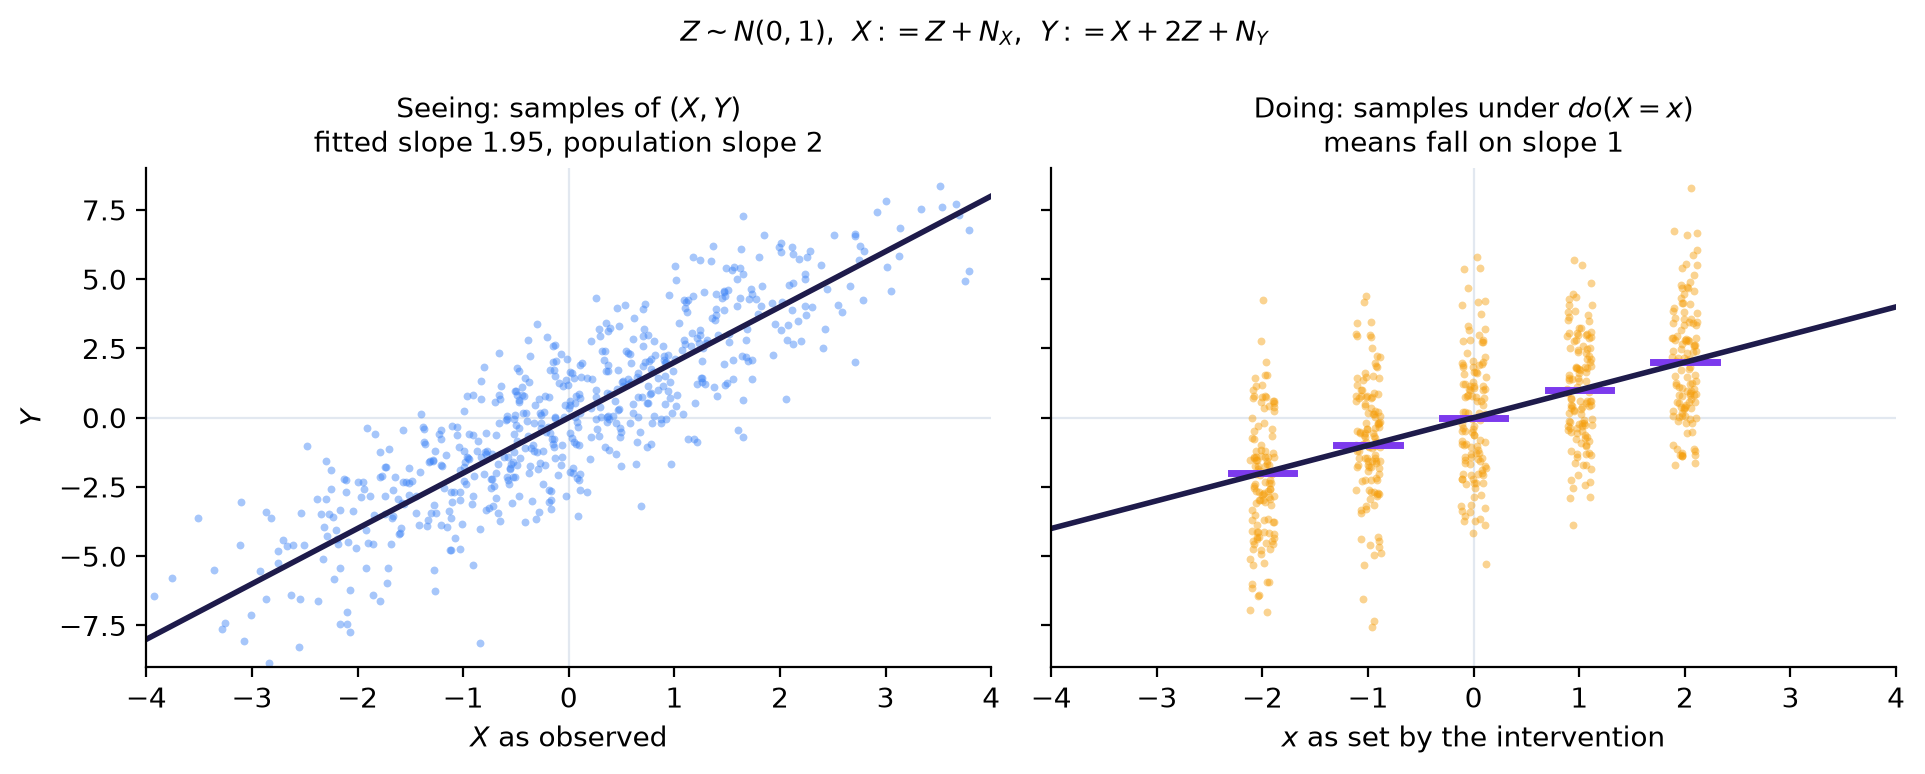

In [3]:
_show_mpl(_lessonfigs.slopes_figure())

*The same story with continuous variables. In $Z \sim N(0,1)$, $X := Z + N_X$, $Y := X + 2Z + N_Y$ the regression slope of $Y$ on $X$ is $\mathrm{Cov}(X, Y)/\mathrm{Var}(X) = (2 + 2)/2 = 2$, but setting $X$ moves the mean of $Y$ with slope 1. The purple ticks on the right are the interventional means $\mathbb{E}[Y \mid do(X = x)] = x$.*

## Compute it

Simulate the binary model twice: once as written (seeing), once with the assignment of $X$ replaced (doing). The course engine `qcai.science.causal` gives the exact values. The last lines adjust for $Z$ using only the observational sample.


In [4]:
import numpy as np
from qcai import science

# The binary SCM  Z -> X -> Y <- Z  with the course engine's default numbers.
rng = np.random.default_rng(2024)
n = 400_000
c = 0.5                                   # confounding strength: how much Z raises the risk of Y

def run(n, do_x=None):
    z = rng.random(n) < 0.5                                   # Z := U_Z
    if do_x is None:
        x = rng.random(n) < np.where(z, 0.8, 0.2)              # X := f_X(Z, U_X)
    else:
        x = np.full(n, bool(do_x))                             # X := x   (graph surgery)
    y = rng.random(n) < 0.1 + 0.2 * x + c * z                  # Y := f_Y(X, Z, U_Y), unchanged
    return z, x, y

z, x, y = run(n)
see1, see0 = y[x].mean(), y[~x].mean()
do1 = run(n, do_x=1)[2].mean()
do0 = run(n, do_x=0)[2].mean()
exact = science.causal(0.5, 0.2, 0.8, 0.1, 0.2, c)
print(f"seeing  P(Y=1|X=1) = {see1:.3f}  (exact {exact['treated']:.2f})")
print(f"seeing  P(Y=1|X=0) = {see0:.3f}  (exact {exact['untreated']:.2f})")
print(f"doing   P(Y=1|do(X=1)) = {do1:.3f}  (exact {exact['do1']:.2f})")
print(f"doing   P(Y=1|do(X=0)) = {do0:.3f}  (exact {exact['do0']:.2f})")

# Adjustment for the parent Z uses only observational data and recovers the interventional risk.
adj1 = sum(y[x & (z == v)].mean() * (z == v).mean() for v in (0, 1))
print(f"adjusted sum_z P(Y=1|X=1,z)P(z) = {adj1:.3f}")

seeing  P(Y=1|X=1) = 0.702  (exact 0.70)
seeing  P(Y=1|X=0) = 0.200  (exact 0.20)
doing   P(Y=1|do(X=1)) = 0.550  (exact 0.55)
doing   P(Y=1|do(X=0)) = 0.350  (exact 0.35)
adjusted sum_z P(Y=1|X=1,z)P(z) = 0.552


The continuous model and the toy model. Regression recovers the observational slope 2; the interventional slope is 1. In the toy model the observed contrast is 3 and the causal contrast is 2.


In [5]:
# Linear-Gaussian SCM:  Z ~ N(0,1),  X := Z + N_X,  Y := X + 2Z + N_Y
rng = np.random.default_rng(7)
n = 200_000
zl = rng.normal(size=n)
xl = zl + rng.normal(size=n)
yl = xl + 2 * zl + rng.normal(size=n)
slope_obs = np.cov(xl, yl)[0, 1] / np.var(xl, ddof=1)

# do(X = x) for two values of x: replace X's equation, keep Y's equation and the noise law
def mean_y_do(xv):
    zz = rng.normal(size=n)
    return np.mean(xv + 2 * zz + rng.normal(size=n))

slope_do = (mean_y_do(1.0) - mean_y_do(-1.0)) / 2
print(f"regression slope of Y on X: {slope_obs:.3f}   (population value 2)")
print(f"interventional slope d E[Y|do(x)]/dx: {slope_do:.3f}   (population value 1)")

# The toy model with a shared background input: X := U, Y := 2X + U
u = rng.random(n) < 0.5
xt, yt = u.astype(int), 2 * u + u
print("toy model, seeing:", yt[xt == 1].mean() - yt[xt == 0].mean())
print("toy model, doing: ", np.mean(2 * 1 + u) - np.mean(2 * 0 + u))

regression slope of Y on X: 2.004   (population value 2)
interventional slope d E[Y|do(x)]/dx: 0.998   (population value 1)
toy model, seeing: 3.0
toy model, doing:  2.0


:::{prf:remark} Three kinds of question
Pearl's ladder sorts questions by what they need [@pearlcausality; @bareinboim]. **Association** ($P(y \mid x)$) needs only the observational distribution. **Intervention** ($P(y \mid do(x))$) needs the mechanisms, or assumptions that let you identify them from data ([L4-04](#lesson-l4-04) to [L4-07](#lesson-l4-07)). **Counterfactuals** (what would $Y$ have been for this unit, had $X$ been different) need the full SCM including the background distribution; they are the subject of [L4-09](#lesson-l4-09).
:::

## Worked example

:::{admonition} Seeing and doing in the binary model, by hand
:class: tip

In the engine's model ($P(Z = 1) = 0.5$; $P(X = 1 \mid Z) = 0.8$ or $0.2$; $P(Y = 1 \mid X, Z) = 0.1 + 0.2X + 0.5Z$) compute $P(Y = 1 \mid X = 1)$ and $P(Y = 1 \mid do(X = 1))$.

1. Marginal of the treatment: $P(X = 1) = 0.5 \cdot 0.8 + 0.5 \cdot 0.2 = 0.5$.
2. Bayes' rule for the confounder among the treated: $P(Z = 1 \mid X = 1) = 0.5 \cdot 0.8 / 0.5 = 0.8$.
3. Outcome risks within strata of the treated: $P(Y = 1 \mid X = 1, Z = 1) = 0.8$ and $P(Y = 1 \mid X = 1, Z = 0) = 0.3$.
4. Seeing averages them with the treated weights: $0.8 \cdot 0.8 + 0.2 \cdot 0.3 = 0.64 + 0.06 = 0.70$.
5. Doing averages them with the population weights (Corollary [](#cor-l4-01-parents)): $0.5 \cdot 0.8 + 0.5 \cdot 0.3 = 0.55$.

**Result.** $P(Y = 1 \mid X = 1) = 0.70$ but $P(Y = 1 \mid do(X = 1)) = 0.55$. The difference comes entirely from the weight on $Z$.
:::

## Exercises

**1. (Core)** Change the toy model to $X := U$, $Y := 3X + 2U$ with the same fair coin $U$. Find the observed contrast and the intervention contrast.

:::{dropdown} Solution
Observed: $U = 1$ gives $X = 1$, $Y = 5$; $U = 0$ gives $X = 0$, $Y = 0$. The observed contrast is $5 - 0 = 5$. Under $do(X = x)$, $Y = 3x + 2U$ with $\mathbb{E}[Y \mid do(X = x)] = 3x + 1$, so the means are 4 and 1 and the causal contrast is 3.
:::

**2. (Core)** In the binary model with $c = 0.5$, compute $P(Y = 1 \mid X = 0)$ and $P(Y = 1 \mid do(X = 0))$.

:::{dropdown} Solution
$P(X = 0) = 0.5$ and $P(Z = 1 \mid X = 0) = 0.5 \cdot 0.2 / 0.5 = 0.2$. The risks are $P(Y = 1 \mid X = 0, Z = 1) = 0.6$ and $P(Y = 1 \mid X = 0, Z = 0) = 0.1$. Seeing: $0.2 \cdot 0.6 + 0.8 \cdot 0.1 = 0.20$. Doing: $0.5 \cdot 0.6 + 0.5 \cdot 0.1 = 0.35$.
:::

**3. (Stretch)** Let $Z \sim N(0,1)$, $X := aZ + N_X$, $Y := bX + gZ + N_Y$ with independent standard normal noises. Show that the regression slope of $Y$ on $X$ is $b + ag/(a^2 + 1)$ while $\frac{d}{dx}\mathbb{E}[Y \mid do(X = x)] = b$. Check $a = 1$, $b = 1$, $g = 2$.

:::{dropdown} Solution
$\mathrm{Var}(X) = a^2 + 1$ and $\mathrm{Cov}(X, Z) = a$. $\mathrm{Cov}(X, Y) = b\,\mathrm{Var}(X) + g\,\mathrm{Cov}(X, Z) = b(a^2 + 1) + ag$, so the slope is $b + ag/(a^2 + 1)$. Under $do(X = x)$, $Y = bx + gZ + N_Y$ and $\mathbb{E}[Y \mid do(X = x)] = bx$, slope $b$. With $a = 1, b = 1, g = 2$: $1 + 2/2 = 2$ versus 1, as in the figure.
:::

**4. (Stretch)** Use the truncated factorization to prove: in a Markovian model, if $X$ has no parents, then $P(y \mid do(x)) = P(y \mid x)$ whenever $P(x) > 0$.

:::{dropdown} Solution
With $\mathrm{PA}_X = \emptyset$ the factor of $X$ is $P(x)$, so for $v$ agreeing with $x$, $P(v \mid do(x)) = P(v)/P(x)$. Summing over all variables except $Y$ (with $X$ fixed at $x$) gives $P(y \mid do(x)) = P(y, x)/P(x) = P(y \mid x)$. This is why randomizing $X$ (which makes it parentless) lets the observed contrast estimate the causal one, as in [L2-08](#lesson-l2-08).
:::

**5. (Challenge)** Model A: $X := U_X$, $Y := X$. Model B: $Y := U_Y$, $X := Y$. Both $U$'s are fair coins. Show that the two models have the same observational distribution but different $P(Y = 1 \mid do(X = 1))$. What does this say about learning interventions from $P(V)$ alone?

:::{dropdown} Solution
In both models $X = Y$ always and each is a fair coin, so $P(X = Y = 0) = P(X = Y = 1) = 1/2$ in both. In Model A, $do(X = 1)$ keeps $Y := X$, so $P(Y = 1 \mid do(X = 1)) = 1$. In Model B, $do(X = 1)$ replaces $X := Y$ and leaves $Y := U_Y$, so $P(Y = 1 \mid do(X = 1)) = 1/2$. The observational distribution does not determine the interventional one; extra assumptions (a graph, an experiment) are needed. [L4-07](#lesson-l4-07) develops this as identification.
:::

## Check your understanding

**1. What does the ideal intervention $do(X = x)$ change in a structural causal model?**

- **A.** It replaces every assignment in the model
- **B.** It changes the background distribution $P(U)$
- **C.** It keeps only the records in which $X = x$
- **D.** It replaces the assignment of $X$ by the constant $x$ and keeps the other assignments and $P(U)$

:::{dropdown} Show the answer
**D. It replaces the assignment of $X$ by the constant $x$ and keeps the other assignments and $P(U)$**

An ideal intervention is modular: exactly the mechanism of $X$ is replaced. Keeping only the records with $X = x$ is conditioning, which is a different operation.
:::

**2. In $U \sim \mathrm{Bernoulli}(1/2)$, $X := U$, $Y := 2X + U$, what is $\mathbb{E}[Y \mid do(X = 1)]$?**

- **A.** 3
- **B.** 2.5
- **C.** 0.5
- **D.** 2

:::{dropdown} Show the answer
**B. 2.5**

Under $do(X = 1)$, $Y = 2 + U$ with $\mathbb{E}[U] = 1/2$, so the mean is 2.5. The value 3 is $\mathbb{E}[Y \mid X = 1]$, which conditions on $U = 1$.
:::

**3. In the binary model, $P(Y = 1 \mid X = 1) = 0.70$ but $P(Y = 1 \mid do(X = 1)) = 0.55$. Why?**

- **A.** The intervention changes the mechanism of $Y$
- **B.** The sample is too small
- **C.** Treated records contain more $Z = 1$ units than the population, and $Z$ raises the risk of $Y$ directly
- **D.** $X$ has no effect on $Y$

:::{dropdown} Show the answer
**C. Treated records contain more $Z = 1$ units than the population, and $Z$ raises the risk of $Y$ directly**

Both quantities average the same stratum risks 0.8 and 0.3. Seeing uses $P(Z = 1 \mid X = 1) = 0.8$, doing uses $P(Z = 1) = 0.5$. The values are exact, so sample size plays no role, and $X$ does have an effect of 0.2.
:::

**4. $U$ is a fair coin coded 0 or 1, and $x$ is a fixed number. What is $\mathbb{E}[2x + U]$?** *(Review of [L3-07](#lesson-l3-07))*

- **A.** $2x$
- **B.** $x + \tfrac{1}{2}$
- **C.** $2x + \tfrac{1}{2}$
- **D.** $2x + 1$

:::{dropdown} Show the answer
**C. $2x + \tfrac{1}{2}$**

Expectation is linear: $\mathbb{E}[2x + U] = 2x + \mathbb{E}[U] = 2x + 1/2$. This one line is the whole interventional calculation in the toy model.
:::

## Common misconceptions

- **"A structural equation is just a regression equation."** A regression describes $\mathbb{E}[Y \mid X]$ in the observed population. A structural assignment states how $Y$ would respond if its inputs were changed. In the toy model the regression is $Y = 3X$ but the assignment is $Y := 2X + U$.
- **"$P(Y \mid do(X = x))$ is $P(Y \mid X = x)$ in a cleaner dataset."** They are different quantities defined by different models ($M_x$ versus $M$). They coincide only under conditions on the graph, for example when $X$ has no parents or when no noncausal path links $X$ and $Y$.
- **"If a model predicts well, its interventional answers are right."** Models A and B in the challenge exercise predict identically and disagree about every intervention. Predictive accuracy constrains $P(V)$, not the mechanisms.

:::{caution} Scope and limits
An ideal intervention is a modeling idealization: it changes exactly one mechanism and nothing else. A real action (a policy, a drug, a nudge) may change several mechanisms, or change the mechanism only for some units, and should then be modeled explicitly. The truncated factorization assumes a Markovian model (independent background terms, no cycles) and positivity where conditionals are used. Everything here is computed from fully specified models and simulations; deciding whether a real system is described by a given SCM is a separate, empirical question.
:::

:::{seealso} Where this leads
The do-operator and the truncated factorization are the foundation for the rest of Level 4. [L4-02](#lesson-l4-02) reads conditional independences off the induced graph, [L4-03](#lesson-l4-03) sorts variables into confounders, mediators and colliders, and [L4-04](#lesson-l4-04) generalizes the parent adjustment of Corollary [](#cor-l4-01-parents) to the backdoor criterion. In Level 6 the same idea, replacing one mechanism while keeping the others, reappears for quantum causal models.
:::

:::{dropdown} For instructors

**Why this lesson.** Students arrive with regression and with the slogan that correlation is not causation. The SCM turns that slogan into a definition: an intervention is a specific modification of a model, and its consequences can be computed and compared with conditioning [@pearlcausality; @peters; @hernan].

**Teaching notes.**

- Start with the three-line toy model and ask the class to predict the effect of pushing $X$ from 0 to 1 before anyone fits a line. Most will say 3.
- Insist on $:=$ for assignments for the first week; ask students to rewrite $Y := 2X + U$ as an assignment for $X$ and discuss why that changes the model.
- Use the interactive to show that the bias $0.6c$ vanishes exactly when $c = 0$, then ask what other change to the model would remove it (making $X$ independent of $Z$, that is, $P(X = 1 \mid Z)$ the same for both values of $Z$).
- The proof of the Markov factorization is short and worth doing on the board: it explains where independent background terms are used.

**Assessment.** The second core exercise and the worked example test the computation; the stretch exercise on the linear model tests whether students can derive omitted-variable bias from the structure; the challenge exercise tests the conceptual point that $P(V)$ does not fix interventions.

**Going further.** Have students add a mediator $M$ between $X$ and $Y$ and verify by simulation that the truncated factorization still holds. Brady Neal's notes give a gentle parallel treatment [@bradyneal], and Peters, Janzing and Schölkopf discuss SCMs with noise terms and their identifiability [@peters].

:::

## References

This lesson draws on [@pearlcausality; @pearl; @peters; @hernan; @bareinboim; @bradyneal].

**Further reading.**

- [@bradyneal]: Chapters on SCMs and the do-operator, with many small worked graphs.
- [@seeing]: The Mixtape's chapter on directed acyclic graphs gives applied examples of seeing versus doing.

**Next:** [L4-02 · DAGs and d-separation](#lesson-l4-02)
